In [1]:
# Cellule 1 - Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')
os.makedirs('leakage_results', exist_ok=True)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score,
                             balanced_accuracy_score,
                             f1_score,
                             matthews_corrcoef,
                             classification_report,
                             confusion_matrix)

print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))
print('Imports OK')

TensorFlow : 2.20.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Imports OK


In [2]:
# Cellule 2 - Chargement depuis Google Drive
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/UCI HAR Dataset'

# Features avec noms uniques
with open(f'{BASE}/features.txt') as f:
    features_raw = [line.strip().split(' ', 1)[1] for line in f.readlines()]

seen = {}
features_unique = []
for feat in features_raw:
    if feat in seen:
        seen[feat] += 1
        features_unique.append(feat + '_' + str(seen[feat]))
    else:
        seen[feat] = 0
        features_unique.append(feat)

# Charger X train et test
X_train_raw = pd.read_csv(
    f'{BASE}/train/X_train.txt',
    sep=r'\s+', engine='python',
    header=None, names=features_unique
)
X_test_raw = pd.read_csv(
    f'{BASE}/test/X_test.txt',
    sep=r'\s+', engine='python',
    header=None, names=features_unique
)

# Charger y et subjects
y_train_raw     = pd.read_csv(f'{BASE}/train/y_train.txt', header=None)[0]
y_test_raw      = pd.read_csv(f'{BASE}/test/y_test.txt',   header=None)[0]
subject_train   = pd.read_csv(f'{BASE}/train/subject_train.txt', header=None)[0]
subject_test    = pd.read_csv(f'{BASE}/test/subject_test.txt',   header=None)[0]

# Combiner train et test
X_all = np.concatenate([X_train_raw.values, X_test_raw.values], axis=0)
y_all = np.concatenate([y_train_raw.values, y_test_raw.values], axis=0)
s_all = np.concatenate([subject_train.values, subject_test.values], axis=0)

# Encodage labels
le        = LabelEncoder()
y_all_enc = le.fit_transform(y_all)

CLASS_NAMES = ['LAYING', 'SITTING', 'STANDING', 'WALKING',
               'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']

print('Total samples :', len(X_all))
print('Total sujets  :', len(np.unique(s_all)))
print('Sujets        :', sorted(np.unique(s_all).tolist()))
print('Donnees chargees')

Mounted at /content/drive
Total samples : 10299
Total sujets  : 30
Sujets        : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
Donnees chargees


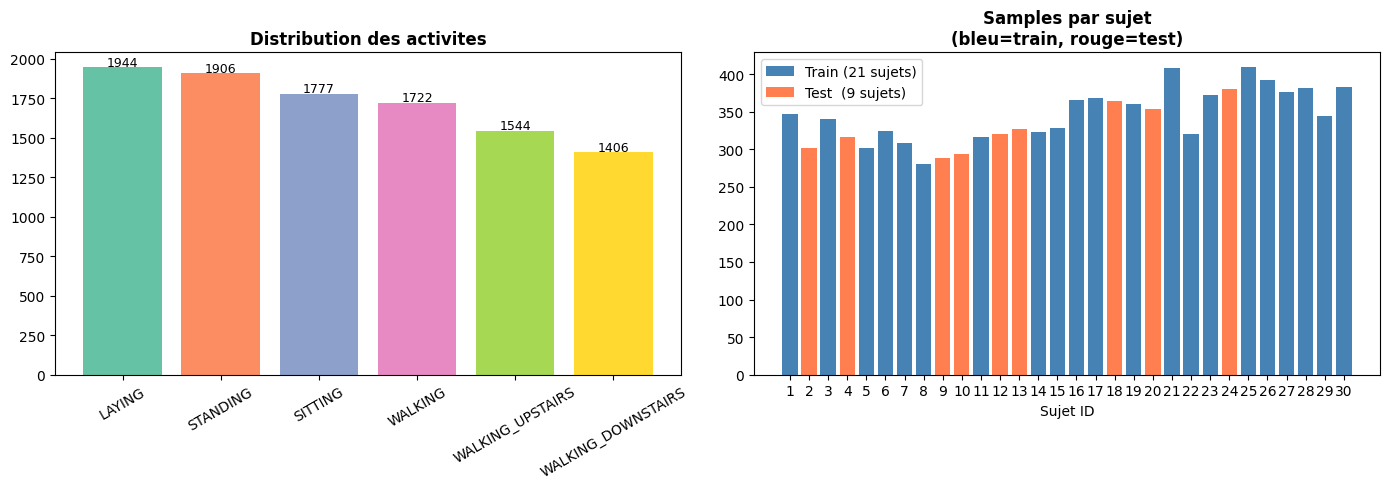

In [3]:
# Cellule 3 - Distribution des activites et sujets
label_map = {1:'WALKING', 2:'WALKING_UPSTAIRS', 3:'WALKING_DOWNSTAIRS',
             4:'SITTING', 5:'STANDING', 6:'LAYING'}
y_all_names = np.array([label_map[v] for v in y_all])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution activites
act_counts = pd.Series(y_all_names).value_counts()
axes[0].bar(act_counts.index, act_counts.values,
            color=sns.color_palette('Set2', len(act_counts)))
axes[0].set_title('Distribution des activites', fontweight='bold')
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(act_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontsize=9)

# Distribution sujets
subj_counts = pd.Series(s_all).value_counts().sort_index()
colors_subj = ['coral' if s in [2,4,9,10,12,13,18,20,24]
               else 'steelblue' for s in subj_counts.index]
axes[1].bar(subj_counts.index.astype(str), subj_counts.values, color=colors_subj)
axes[1].set_title('Samples par sujet\n(bleu=train, rouge=test)', fontweight='bold')
axes[1].set_xlabel('Sujet ID')

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue', label='Train (21 sujets)'),
                   Patch(facecolor='coral',     label='Test  (9 sujets)')]
axes[1].legend(handles=legend_elements)

plt.tight_layout()
plt.savefig('leakage_results/distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
# Cellule 4 - SPLIT ALEATOIRE (avec leakage)
print('=' * 55)
print('  METHODE 1 : SPLIT ALEATOIRE (avec leakage)')
print('=' * 55)

X_train_rand, X_test_rand, y_train_rand, y_test_rand, s_train_rand, s_test_rand = \
    train_test_split(
        X_all, y_all_enc, s_all,
        test_size=0.2,
        random_state=42,
        stratify=y_all_enc
    )

scaler_rand  = StandardScaler()
X_train_rand = scaler_rand.fit_transform(X_train_rand)
X_test_rand  = scaler_rand.transform(X_test_rand)

# Verifier le leakage
train_subjects_rand = set(np.unique(s_train_rand).tolist())
test_subjects_rand  = set(np.unique(s_test_rand).tolist())
overlap_rand        = train_subjects_rand & test_subjects_rand

print('Train samples :', len(X_train_rand))
print('Test  samples :', len(X_test_rand))
print('Sujets en commun :', len(overlap_rand), '->', sorted(overlap_rand))
print('=> LEAKAGE DETECTE :', len(overlap_rand), 'sujets en commun !')

# Entrainer MLP simple
mlp_rand = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=500,
    random_state=42,
    verbose=False
)
mlp_rand.fit(X_train_rand, y_train_rand)
y_pred_rand = mlp_rand.predict(X_test_rand)

acc_rand     = accuracy_score(y_test_rand, y_pred_rand)
bal_rand     = balanced_accuracy_score(y_test_rand, y_pred_rand)
f1_rand      = f1_score(y_test_rand, y_pred_rand, average='macro')
mcc_rand     = matthews_corrcoef(y_test_rand, y_pred_rand)

print('\nResultats MLP (split aleatoire) :')
print('  Accuracy          :', round(acc_rand*100, 2), '%  <- GONFLEE PAR LEAKAGE')
print('  Balanced Accuracy :', round(bal_rand, 4))
print('  Macro F1          :', round(f1_rand, 4))
print('  MCC               :', round(mcc_rand, 4))

  METHODE 1 : SPLIT ALEATOIRE (avec leakage)
Train samples : 8239
Test  samples : 2060
Sujets en commun : 30 -> [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
=> LEAKAGE DETECTE : 30 sujets en commun !

Resultats MLP (split aleatoire) :
  Accuracy          : 98.45 %  <- GONFLEE PAR LEAKAGE
  Balanced Accuracy : 0.9855
  Macro F1          : 0.9855
  MCC               : 0.9813


In [5]:
# Cellule 5 - SPLIT PAR SUJET (sans leakage)
print('=' * 55)
print('  METHODE 2 : SPLIT PAR SUJET (sans leakage)')
print('=' * 55)

# Sujets test officiels UCI HAR
test_subjects_subj  = [2, 4, 9, 10, 12, 13, 18, 20, 24]
train_subjects_subj = [s for s in sorted(np.unique(s_all).tolist())
                       if s not in test_subjects_subj]

train_mask = np.isin(s_all, train_subjects_subj)
test_mask  = np.isin(s_all, test_subjects_subj)

X_train_subj = X_all[train_mask]
X_test_subj  = X_all[test_mask]
y_train_subj = y_all_enc[train_mask]
y_test_subj  = y_all_enc[test_mask]

scaler_subj  = StandardScaler()
X_train_subj = scaler_subj.fit_transform(X_train_subj)
X_test_subj  = scaler_subj.transform(X_test_subj)

overlap_subj = set(train_subjects_subj) & set(test_subjects_subj)

print('Train samples :', len(X_train_subj), '| Sujets :', train_subjects_subj)
print('Test  samples :', len(X_test_subj),  '| Sujets :', test_subjects_subj)
print('Sujets en commun :', overlap_subj if overlap_subj else 'AUCUN - pas de leakage')

# Entrainer MLP simple
mlp_subj = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=500,
    random_state=42,
    verbose=False
)
mlp_subj.fit(X_train_subj, y_train_subj)
y_pred_subj = mlp_subj.predict(X_test_subj)

acc_subj  = accuracy_score(y_test_subj, y_pred_subj)
bal_subj  = balanced_accuracy_score(y_test_subj, y_pred_subj)
f1_subj   = f1_score(y_test_subj, y_pred_subj, average='macro')
mcc_subj  = matthews_corrcoef(y_test_subj, y_pred_subj)

print('\nResultats MLP (split par sujet) :')
print('  Accuracy          :', round(acc_subj*100, 2), '%  <- RESULTAT REEL')
print('  Balanced Accuracy :', round(bal_subj, 4))
print('  Macro F1          :', round(f1_subj, 4))
print('  MCC               :', round(mcc_subj, 4))

  METHODE 2 : SPLIT PAR SUJET (sans leakage)
Train samples : 7352 | Sujets : [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Test  samples : 2947 | Sujets : [2, 4, 9, 10, 12, 13, 18, 20, 24]
Sujets en commun : AUCUN - pas de leakage

Resultats MLP (split par sujet) :
  Accuracy          : 95.11 %  <- RESULTAT REEL
  Balanced Accuracy : 0.9497
  Macro F1          : 0.9509
  MCC               : 0.9416


In [6]:
# Cellule 6 - Quantifier le leakage
inflation_acc  = acc_rand  - acc_subj
inflation_bal  = bal_rand  - bal_subj
inflation_f1   = f1_rand   - f1_subj
inflation_mcc  = mcc_rand  - mcc_subj

print('\n' + '=' * 60)
print('       RAPPORT DATA LEAKAGE - UCI HAR')
print('=' * 60)
print('{:<22} {:>12} {:>12} {:>10}'.format(
    'Metrique', 'Split Rand', 'Split Sujet', 'Inflation'))
print('-' * 60)
print('{:<22} {:>11.2f}% {:>11.2f}% {:>+9.2f}%'.format(
    'Accuracy', acc_rand*100, acc_subj*100, inflation_acc*100))
print('{:<22} {:>12.4f} {:>12.4f} {:>+10.4f}'.format(
    'Balanced Accuracy', bal_rand, bal_subj, inflation_bal))
print('{:<22} {:>12.4f} {:>12.4f} {:>+10.4f}'.format(
    'Macro F1', f1_rand, f1_subj, inflation_f1))
print('{:<22} {:>12.4f} {:>12.4f} {:>+10.4f}'.format(
    'MCC', mcc_rand, mcc_subj, inflation_mcc))
print('=' * 60)

if inflation_acc > 0.02:
    print('CONCLUSION : Leakage SIGNIFICATIF detecte !')
    print('Le split aleatoire surestime l accuracy de',
          round(inflation_acc*100, 2), '%')
    print('=> Utiliser OBLIGATOIREMENT le split par sujet')
else:
    print('CONCLUSION : Leakage faible (<2%)')
print('=' * 60)


       RAPPORT DATA LEAKAGE - UCI HAR
Metrique                 Split Rand  Split Sujet  Inflation
------------------------------------------------------------
Accuracy                     98.45%       95.11%     +3.33%
Balanced Accuracy            0.9855       0.9497    +0.0358
Macro F1                     0.9855       0.9509    +0.0346
MCC                          0.9813       0.9416    +0.0397
CONCLUSION : Leakage SIGNIFICATIF detecte !
Le split aleatoire surestime l accuracy de 3.33 %
=> Utiliser OBLIGATOIREMENT le split par sujet


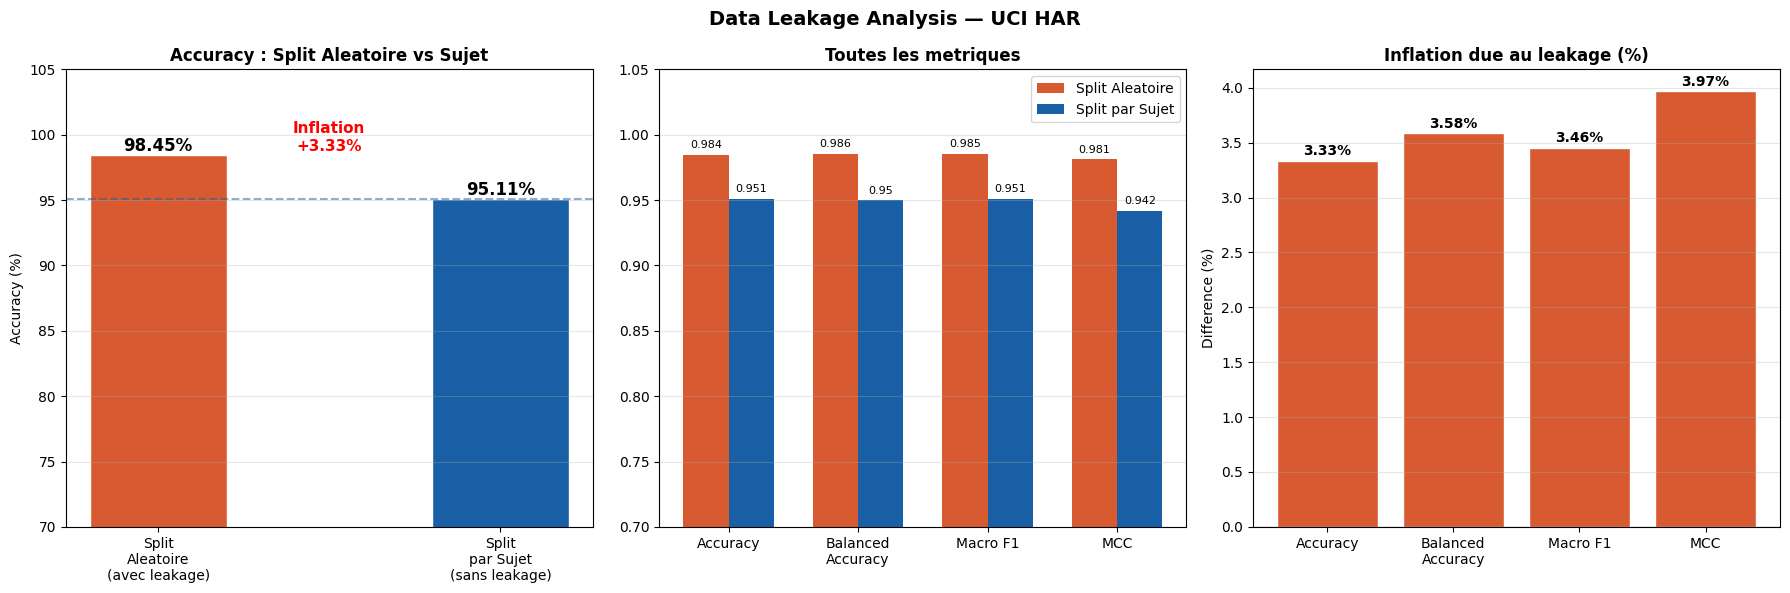

In [7]:
# Cellule 7 - Visualisations
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Data Leakage Analysis — UCI HAR',
             fontsize=14, fontweight='bold')

# ── Graphique 1 : Accuracy comparison ────────
methods = ['Split\nAleatoire\n(avec leakage)', 'Split\npar Sujet\n(sans leakage)']
accs    = [acc_rand*100, acc_subj*100]
colors  = ['#D85A30', '#185FA5']
bars    = axes[0].bar(methods, accs, color=colors, width=0.4, edgecolor='white')
for bar, val in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 str(round(val, 2)) + '%',
                 ha='center', fontsize=12, fontweight='bold')
axes[0].set_ylim(70, 105)
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Accuracy : Split Aleatoire vs Sujet',
                  fontweight='bold')
axes[0].axhline(y=acc_subj*100, color='#185FA5',
                linestyle='--', alpha=0.5)
axes[0].grid(axis='y', alpha=0.3)
axes[0].annotate('Inflation\n+' + str(round(inflation_acc*100, 2)) + '%',
                 xy=(0.5, (acc_rand + acc_subj)/2*100),
                 xytext=(0.5, (acc_rand + acc_subj)/2*100 + 2),
                 ha='center', fontsize=11,
                 color='red', fontweight='bold')

# ── Graphique 2 : Toutes les metriques ────────
metrics_names  = ['Accuracy', 'Balanced\nAccuracy', 'Macro F1', 'MCC']
metrics_rand   = [acc_rand,   bal_rand,  f1_rand,  mcc_rand]
metrics_subj   = [acc_subj,   bal_subj,  f1_subj,  mcc_subj]
x     = np.arange(len(metrics_names))
width = 0.35
b1 = axes[1].bar(x - width/2, metrics_rand, width,
                 label='Split Aleatoire', color='#D85A30')
b2 = axes[1].bar(x + width/2, metrics_subj, width,
                 label='Split par Sujet', color='#185FA5')
axes[1].set_xticks(x)
axes[1].set_xticklabels(metrics_names)
axes[1].set_ylim(0.7, 1.05)
axes[1].set_title('Toutes les metriques', fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
for bar in b1:
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.005,
                 str(round(bar.get_height(), 3)),
                 ha='center', fontsize=8)
for bar in b2:
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.005,
                 str(round(bar.get_height(), 3)),
                 ha='center', fontsize=8)

# ── Graphique 3 : Inflation par metrique ──────
inflations = [inflation_acc*100, inflation_bal*100,
              inflation_f1*100, inflation_mcc*100]
colors_inf = ['#D85A30' if v > 0 else '#185FA5' for v in inflations]
axes[2].bar(metrics_names, inflations, color=colors_inf, edgecolor='white')
axes[2].axhline(y=0, color='black', linewidth=0.8)
axes[2].set_title('Inflation due au leakage (%)', fontweight='bold')
axes[2].set_ylabel('Difference (%)')
axes[2].grid(axis='y', alpha=0.3)
for i, val in enumerate(inflations):
    axes[2].text(i, val + 0.05, str(round(val, 2)) + '%',
                 ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('leakage_results/leakage_analysis.png',
            dpi=150, bbox_inches='tight')
plt.show()

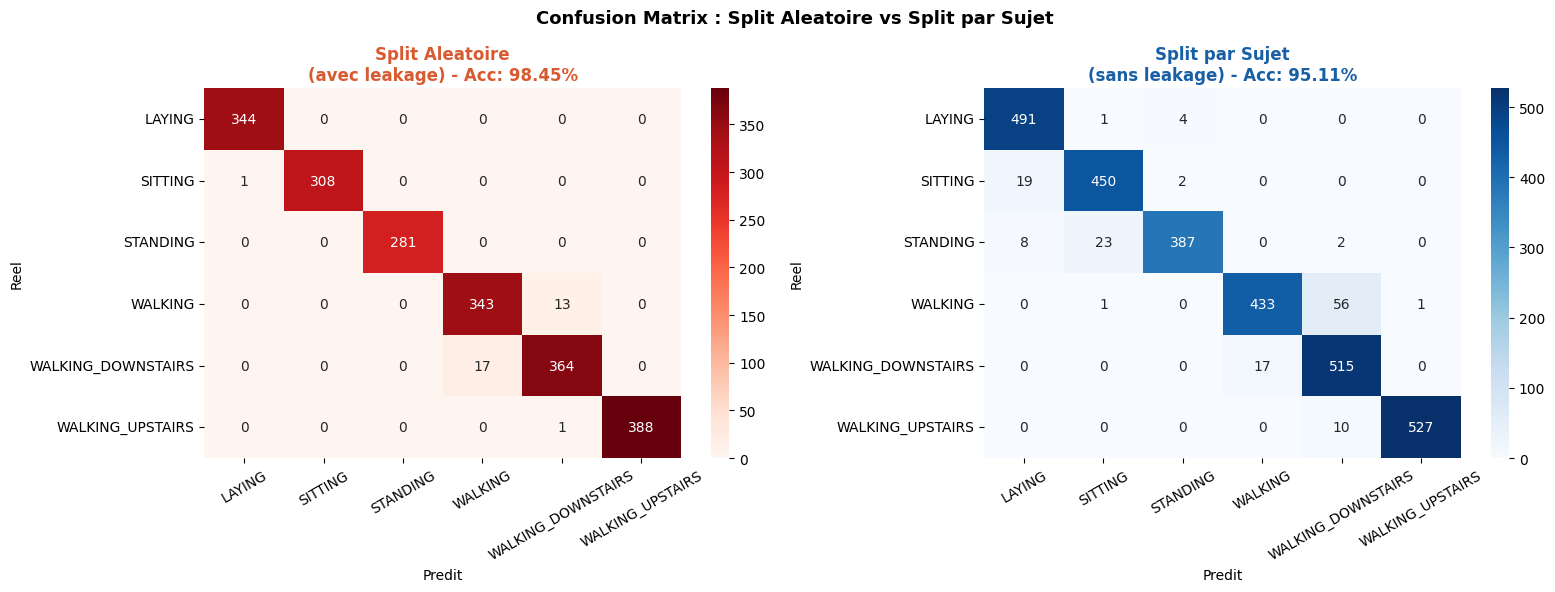

In [8]:
# Cellule 8 - Confusion matrices comparees
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Confusion Matrix : Split Aleatoire vs Split par Sujet',
             fontsize=13, fontweight='bold')

# Split aleatoire
cm_rand = confusion_matrix(y_test_rand, y_pred_rand)
sns.heatmap(cm_rand, annot=True, fmt='d', cmap='Reds',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Split Aleatoire\n(avec leakage) - Acc: ' +
                  str(round(acc_rand*100, 2)) + '%',
                  fontweight='bold', color='#D85A30')
axes[0].set_ylabel('Reel')
axes[0].set_xlabel('Predit')
axes[0].tick_params(axis='x', rotation=30)

# Split par sujet
cm_subj = confusion_matrix(y_test_subj, y_pred_subj)
sns.heatmap(cm_subj, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('Split par Sujet\n(sans leakage) - Acc: ' +
                  str(round(acc_subj*100, 2)) + '%',
                  fontweight='bold', color='#185FA5')
axes[1].set_ylabel('Reel')
axes[1].set_xlabel('Predit')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('leakage_results/confusion_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# Cellule 9 - Deep Learning avec les deux splits
# Entrainer le meme modele DL avec les deux methodes

def build_mlp_dl(input_dim, num_classes):
    inputs = keras.Input(shape=(input_dim,))
    x = layers.Dense(256, activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64,  activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model = Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

NUM_CLASSES = len(np.unique(y_all_enc))

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=0)
]

# ── DL avec split aleatoire ───────────────────
print('Entrainement DL - Split Aleatoire...')
y_train_rand_ohe = to_categorical(y_train_rand, NUM_CLASSES)
y_test_rand_ohe  = to_categorical(y_test_rand,  NUM_CLASSES)

dl_rand = build_mlp_dl(X_train_rand.shape[1], NUM_CLASSES)
dl_rand.fit(X_train_rand, y_train_rand_ohe,
            epochs=100, batch_size=64,
            validation_split=0.1,
            callbacks=callbacks, verbose=0)

y_pred_dl_rand = np.argmax(dl_rand.predict(X_test_rand, verbose=0), axis=1)
acc_dl_rand    = accuracy_score(y_test_rand, y_pred_dl_rand)
print('  DL Split Aleatoire :', round(acc_dl_rand*100, 2), '%')

# ── DL avec split par sujet ───────────────────
print('Entrainement DL - Split par Sujet...')
y_train_subj_ohe = to_categorical(y_train_subj, NUM_CLASSES)
y_test_subj_ohe  = to_categorical(y_test_subj,  NUM_CLASSES)

dl_subj = build_mlp_dl(X_train_subj.shape[1], NUM_CLASSES)
dl_subj.fit(X_train_subj, y_train_subj_ohe,
            epochs=100, batch_size=64,
            validation_split=0.1,
            callbacks=callbacks, verbose=0)

y_pred_dl_subj = np.argmax(dl_subj.predict(X_test_subj, verbose=0), axis=1)
acc_dl_subj    = accuracy_score(y_test_subj, y_pred_dl_subj)
print('  DL Split par Sujet :', round(acc_dl_subj*100, 2), '%')

inflation_dl = acc_dl_rand - acc_dl_subj
print('\nInflation DL :', round(inflation_dl*100, 2), '%')

Entrainement DL - Split Aleatoire...
  DL Split Aleatoire : 97.72 %
Entrainement DL - Split par Sujet...
  DL Split par Sujet : 95.39 %

Inflation DL : 2.33 %


In [10]:
# Cellule 10 - Rapport final complet
print('\n' + '=' * 65)
print('        RAPPORT FINAL DATA LEAKAGE ANALYSIS')
print('=' * 65)
print('{:<25} {:>10} {:>12} {:>12}'.format(
    'Modele / Split', 'Rand (leak)', 'Sujet (OK)', 'Inflation'))
print('-' * 65)
print('{:<25} {:>10.2f}% {:>11.2f}% {:>+11.2f}%'.format(
    'MLP (sklearn)',
    acc_rand*100, acc_subj*100, inflation_acc*100))
print('{:<25} {:>10.2f}% {:>11.2f}% {:>+11.2f}%'.format(
    'Deep MLP (Keras)',
    acc_dl_rand*100, acc_dl_subj*100, inflation_dl*100))
print('=' * 65)
print('\nCONCLUSION :')
print('  1. Le split aleatoire cause un leakage de',
      round(inflation_acc*100, 2), '%')
print('  2. Les sujets en commun train/test :',
      len(overlap_rand), 'sur 30')
print('  3. Methode correcte : split par sujet (person-independent)')
print('  4. Preprocessing (normalisation) : fit sur train uniquement')
print('\nPREVENTION APPLIQUEE :')
print('  - StandardScaler : fit sur train, transform sur test')
print('  - Split par sujet : 0 sujet en commun')
print('  - SMOTE/DeepSMOTE : applique apres le split uniquement')
print('=' * 65)

# Sauvegarder le rapport
rapport = pd.DataFrame([
    {'Methode': 'MLP sklearn - Split Aleatoire',
     'Accuracy': round(acc_rand, 4),
     'Bal_Acc': round(bal_rand, 4),
     'Macro_F1': round(f1_rand, 4),
     'MCC': round(mcc_rand, 4),
     'Leakage': 'OUI'},
    {'Methode': 'MLP sklearn - Split Sujet',
     'Accuracy': round(acc_subj, 4),
     'Bal_Acc': round(bal_subj, 4),
     'Macro_F1': round(f1_subj, 4),
     'MCC': round(mcc_subj, 4),
     'Leakage': 'NON'},
    {'Methode': 'Deep MLP Keras - Split Aleatoire',
     'Accuracy': round(acc_dl_rand, 4),
     'Bal_Acc': '-', 'Macro_F1': '-', 'MCC': '-',
     'Leakage': 'OUI'},
    {'Methode': 'Deep MLP Keras - Split Sujet',
     'Accuracy': round(acc_dl_subj, 4),
     'Bal_Acc': '-', 'Macro_F1': '-', 'MCC': '-',
     'Leakage': 'NON'},
])
rapport.to_csv('leakage_results/leakage_rapport.csv', index=False)
print('Rapport sauvegarde : leakage_results/leakage_rapport.csv')


        RAPPORT FINAL DATA LEAKAGE ANALYSIS
Modele / Split            Rand (leak)   Sujet (OK)    Inflation
-----------------------------------------------------------------
MLP (sklearn)                  98.45%       95.11%       +3.33%
Deep MLP (Keras)               97.72%       95.39%       +2.33%

CONCLUSION :
  1. Le split aleatoire cause un leakage de 3.33 %
  2. Les sujets en commun train/test : 30 sur 30
  3. Methode correcte : split par sujet (person-independent)
  4. Preprocessing (normalisation) : fit sur train uniquement

PREVENTION APPLIQUEE :
  - StandardScaler : fit sur train, transform sur test
  - Split par sujet : 0 sujet en commun
  - SMOTE/DeepSMOTE : applique apres le split uniquement
Rapport sauvegarde : leakage_results/leakage_rapport.csv
